# 05 — LBP + KNN / SVM / Random Forest

Same pipeline as notebook 04 (*image → descriptor → classifier*), but with another descriptor from the course (slides 116-121):
**LBP** (Local Binary Patterns), which describes **texture**: how the grey levels change around each pixel (edge, corner, flat zone, spot…).

HOG (notebook 04) looks at **shape** (edge directions). LBP looks at **texture**. Question of this notebook: is texture also enough to recognise the posture?

Everything else is **identical** to notebook 04 (same crops, same 5 video groups, same video decision), so the scores can be compared directly.

In [1]:
from pathlib import Path
import time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.feature import local_binary_pattern

ROOT = Path("..") / "data" / "raw" / "urfd"
PROC = Path("..") / "data" / "processed"
PHASES = {-1: "not lying", 0: "falling", 1: "lying"}

labels = pd.concat([pd.read_csv(ROOT / "labels" / f"urfall-cam0-{k}.csv", header=None, usecols=[0, 1, 2])
                    for k in ["falls", "adls"]], ignore_index=True)
labels.columns = ["video", "frame", "frame_label"]

z = np.load(PROC / "crops64.npz")          # the 64 x 64 person crops made in notebook 04
frames = pd.DataFrame({"video": z["video"], "frame": z["frame"]}).merge(labels, on=["video", "frame"], how="left")
keep = frames.frame_label.notna().to_numpy()
crops, frames = z["crops"][keep], frames[keep].reset_index(drop=True)
frames["phase"] = frames.frame_label.map(PHASES)
gray = np.stack([cv2.cvtColor(c, cv2.COLOR_RGB2GRAY) for c in crops])   # LBP works on grey levels
y = frames.frame_label.astype(int).to_numpy()
print(gray.shape)

(11027, 64, 64)


💡 **Interpretation:** the same **11,027 labelled crops** as notebook 04, turned to grey levels (64 × 64), because LBP only compares brightness between pixels.

## Step 1 — The LBP code of one pixel

The course recipe (slide 117), on a **3 × 3 window**:
1. compare each of the **8 neighbours** with the centre pixel: 1 if the neighbour is ≥ the centre, else 0;
2. read the 8 bits around the circle → a binary number → a code between **0 and 255**.

Here on a real pixel of a crop:

In [2]:
i = frames[frames.phase == "not lying"].index[200]
r, c = 30, 32                                   # a pixel near the middle of the crop
window = gray[i, r - 1:r + 2, c - 1:c + 2].astype(int)
print("3 x 3 grey levels:\n", window)
order = [(0, 0), (0, 1), (0, 2), (1, 2), (2, 2), (2, 1), (2, 0), (1, 0)]   # the 8 neighbours, clockwise
bits = [int(window[p] >= window[1, 1]) for p in order]
print("\nbits (neighbour >= centre):", bits)
print("LBP code =", int("".join(map(str, bits)), 2))

3 x 3 grey levels:
 [[106 100  69]
 [126  57  24]
 [ 68  51  31]]

bits (neighbour >= centre): [1, 1, 1, 0, 0, 0, 1, 1]
LBP code = 227


💡 **Interpretation:** 6 of the 8 neighbours are brighter than the centre (57), giving the bits `11100011` = **227**: a dark pixel at the edge of a bright zone.
Every pixel of the crop gets such a code, which says what the texture looks like right around it.

## Step 2 — Uniform patterns and the LBP image

Of the 256 possible codes, the course keeps the **uniform** ones: codes with **at most 2 changes** 0↔1 around the circle (e.g. `00011100`). There are **58** of them; they are the real structures (edges, corners, line ends, flat zones). All other, noisy codes share **1 extra bin** → **59 bins** (58 + 1).
In scikit-image this is `method="nri_uniform"` (8 neighbours at radius 1).

Below: each crop, its **LBP image** (every pixel replaced by its code) and the **histogram** of the 59 codes.

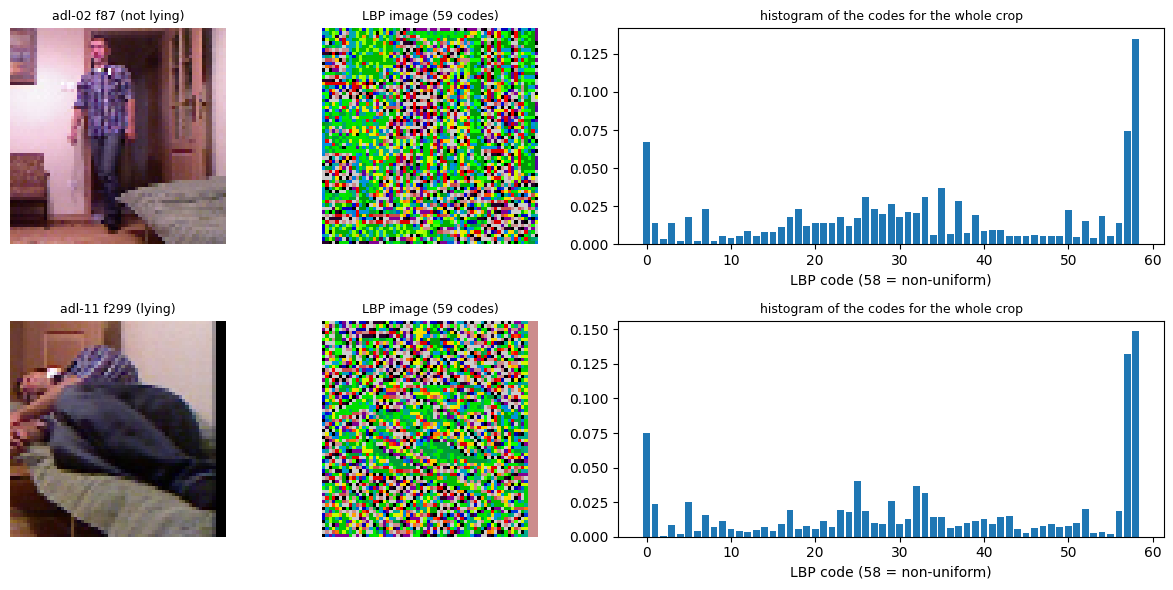

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6), gridspec_kw={"width_ratios": [1, 1, 2.2]})
for row, phase in zip(axes, ["not lying", "lying"]):
    j = frames[frames.phase == phase].index[200]
    codes = local_binary_pattern(gray[j], P=8, R=1, method="nri_uniform")
    row[0].imshow(crops[j]); row[0].set_title(f"{frames.video[j]} f{frames.frame[j]} ({phase})", fontsize=9)
    row[1].imshow(codes, cmap="nipy_spectral"); row[1].set_title("LBP image (59 codes)", fontsize=9)
    row[2].bar(range(59), np.bincount(codes.astype(int).ravel(), minlength=59) / codes.size)
    row[2].set_title("histogram of the codes for the whole crop", fontsize=9); row[2].set_xlabel("LBP code (58 = non-uniform)")
    row[0].axis("off"); row[1].axis("off")
plt.tight_layout(); plt.show()

💡 **Interpretation:** the LBP image follows the body and furniture outlines, but the **two global histograms look almost the same** (same peaks at codes 0, 57, 58):
the whole-crop histogram says *which* textures are present, not *where*, so it hardly sees the posture.

## Step 3 — The same fair test as notebook 04 (split by video)

Same 5 groups of 14 videos as notebooks 02 and 04: a frame is always tested by a model that **never saw its video**.

In [4]:
from sklearn.model_selection import StratifiedKFold, PredefinedSplit, cross_val_predict

videos = np.array(sorted(frames.video.unique()))
is_fall = np.char.startswith(videos, "fall").astype(int)
fold_of = {}
for k, (_, test) in enumerate(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(videos, is_fall)):
    fold_of.update({v: k for v in videos[test]})
frames["fold"] = frames.video.map(fold_of)
cv = PredefinedSplit(frames.fold.to_numpy())
frames.groupby("fold").agg(videos=("video", "nunique"), frames=("video", "size"))

,videos,frames
fold,,
0,14,2175
1,14,2321
2,14,2227
3,14,2044
4,14,2260


💡 **Interpretation:** the same 5 groups of **14 videos** as notebooks 02 and 04, so LBP is tested on exactly the same frames as HOG.

## Step 4 — One histogram for the whole crop, or one per region?

A single histogram says **which** textures are in the crop, but not **where** they are: a standing and a lying person can contain the same edges, only placed differently.
The classic fix (used for faces with LBP) is to cut the image into a **grid** of regions, compute one 59-bin histogram per region, and put them side by side.

We test 3 grids with the fast KNN classifier:
- 1 × 1 → 59 numbers,
- 2 × 2 → 4 × 59 = 236 numbers,
- 4 × 4 → 16 × 59 = 944 numbers.

In [5]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score

codes = np.stack([local_binary_pattern(g, P=8, R=1, method="nri_uniform") for g in gray]).astype(int)

def lbp_histograms(codes, grid):
    side = codes.shape[1] // grid
    parts = []
    for a in range(grid):
        for b in range(grid):
            region = codes[:, a * side:(a + 1) * side, b * side:(b + 1) * side].reshape(len(codes), -1)
            parts.append(np.stack([np.bincount(r, minlength=59) for r in region]) / region.shape[1])
    return np.hstack(parts)

rows = []
for grid in [1, 2, 4]:
    X = lbp_histograms(codes, grid)
    p = cross_val_predict(KNeighborsClassifier(n_neighbors=5), X, y, cv=cv)
    rows.append({"grid": f"{grid} x {grid}", "numbers per frame": X.shape[1],
                 "frame accuracy": accuracy_score(y, p), "macro F1": f1_score(y, p, average="macro")})
pd.DataFrame(rows).round(3)

,grid,numbers per frame,frame accuracy,macro F1
0,1 x 1,59,0.809,0.732
1,2 x 2,236,0.856,0.797
2,4 x 4,944,0.867,0.816


💡 **Interpretation:** one histogram for the whole crop gives only **0.809**; a 4 × 4 grid gives **0.867** (macro F1 0.732 → 0.816). Knowing **where** each texture is matters:
the grid makes LBP see the silhouette's layout. We keep the **4 × 4 grid (944 numbers)**.

## Step 5 — Three classifiers on the 4 × 4 LBP histograms

Same three classifiers and settings as notebook 04.

In [6]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

X = lbp_histograms(codes, 4)
classifiers = {"KNN": KNeighborsClassifier(n_neighbors=5),
               "SVM": SVC(kernel="rbf"),
               "RF": RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=42)}
pred, rows = {}, []
for name, clf in classifiers.items():
    t = time.time()
    pred[name] = cross_val_predict(clf, X, y, cv=cv)
    rows.append({"classifier": name, "frame accuracy": accuracy_score(y, pred[name]),
                 "macro F1": f1_score(y, pred[name], average="macro"), "time (s)": time.time() - t})
frame_scores = pd.DataFrame(rows).round(3)
frame_scores

,classifier,frame accuracy,macro F1,time (s)
0,KNN,0.867,0.816,1.144
1,SVM,0.873,0.810,32.531
2,RF,0.866,0.796,9.360


💡 **Interpretation:** the 3 classifiers are again close (**0.866-0.873**), and all are slightly **better than HOG** (0.855-0.859). KNN has the best macro F1 (**0.816**) and takes 1 s;
RF is much faster than with HOG (10 s vs 136 s) because LBP histograms are simpler to split.

## Step 6 — Which postures are confused? (best classifier)

best: KNN
              precision    recall  f1-score   support

   not lying       0.95      0.91      0.93      7054
     falling       0.59      0.73      0.65      1717
       lying       0.90      0.84      0.87      2256

    accuracy                           0.87     11027
   macro avg       0.81      0.83      0.82     11027
weighted avg       0.88      0.87      0.87     11027



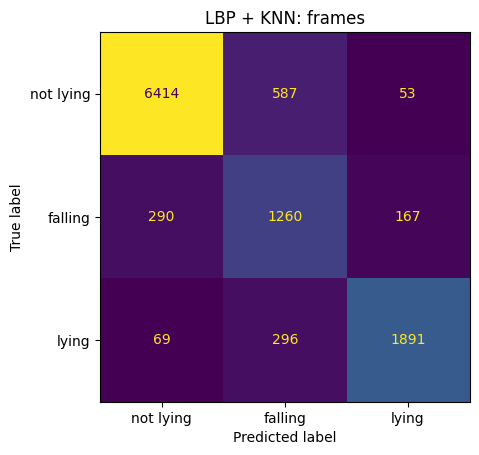

In [7]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

best = frame_scores.sort_values("macro F1").classifier.iloc[-1]
names = [PHASES[k] for k in (-1, 0, 1)]
print("best:", best)
print(classification_report(y, pred[best], target_names=names))
ConfusionMatrixDisplay.from_predictions(y, pred[best], display_labels=names, colorbar=False)
plt.title(f"LBP + {best}: frames"); plt.show()

💡 **Interpretation:** compared with HOG + KNN, *lying* improves a lot (F1 0.81 → **0.87**) but *falling* gets slightly worse (0.67 → **0.65**):
LBP calls **587** *not lying* frames *falling* (423 with HOG), so it raises more "falling" by mistake.

## Step 7 — From frames to the whole video: fall or no fall?

Exactly the same decision as notebook 04: the **share** of each video's frames in each posture → logistic regression, same 5 video groups.

In [8]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import recall_score, precision_score

def video_decision(frame_pred):
    share = pd.crosstab(frames.video, frame_pred, normalize="index").reindex(columns=[-1, 0, 1], fill_value=0)
    share.columns = ["share not lying", "share falling", "share lying"]
    y_video = share.index.str.startswith("fall").astype(int)
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    video_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    return share, y_video, cross_val_predict(model, share, y_video, cv=video_cv)

rows, video_pred = [], {}
for name in classifiers:
    share, y_video, video_pred[name] = video_decision(pred[name])
    rows.append({"classifier": name, "video accuracy": accuracy_score(y_video, video_pred[name]),
                 "recall (falls)": recall_score(y_video, video_pred[name]),
                 "precision (falls)": precision_score(y_video, video_pred[name])})
video_scores = pd.DataFrame(rows).round(3)
share, y_video, _ = video_decision(pred["KNN"])
print(share.groupby(y_video).mean().rename(index={0: "ADL videos", 1: "fall videos"}).round(2))
video_scores

             share not lying  share falling  share lying
ADL videos              0.76           0.12         0.12
fall videos             0.36           0.36         0.27


,classifier,video accuracy,recall (falls),precision (falls)
0,KNN,0.771,0.767,0.719
1,SVM,0.757,0.733,0.710
2,RF,0.786,0.733,0.759


💡 **Interpretation:** better frames, but **worse videos**: 0.771 with KNN (vs 0.857 for HOG + KNN). Yet the average *falling* shares are almost the same as HOG + KNN (ADL 12% vs 11%, falls 36% vs 35%):
the difference comes from a few **borderline videos** (step 8), not from a general weakness.

## Step 8 — Which videos are wrong? Are they the same as with HOG?

In [9]:
share, y_video, _ = video_decision(pred[best])
length = labels.groupby("video").size()
wrong_videos = share.index[video_pred[best] != y_video]
print(f"LBP + {best}: {len(wrong_videos)} wrong videos")
print(pd.DataFrame({"frames in video": length[wrong_videos], "share lying": share.loc[wrong_videos, "share lying"].round(2),
                    "share falling": share.loc[wrong_videos, "share falling"].round(2)}))
hog_wrong = {"fall-01", "fall-03", "fall-05", "fall-07", "fall-09", "adl-31", "adl-32", "adl-33", "adl-34", "adl-35"}  # notebook 04
print("\nalso wrong with HOG + KNN:", sorted(hog_wrong & set(wrong_videos)))

LBP + KNN: 16 wrong videos
         frames in video  share lying  share falling
video                                               
adl-30               369         0.41           0.25
adl-31               250         0.37           0.39
adl-32               200         0.36           0.21
adl-33               200         0.21           0.62
adl-34               191         0.45           0.53
adl-35               280         0.38           0.45
adl-36               323         0.33           0.23
adl-38               327         0.44           0.17
adl-40               286         0.22           0.28
fall-01              160         0.31           0.11
fall-03              215         0.19           0.07
fall-07              156         0.24           0.25
fall-11              130         0.38           0.18
fall-13               85         0.24           0.28
fall-17               95         0.15           0.26
fall-29               99         0.24           0.26

also wrong with HO

💡 **Interpretation:** **16 wrong videos** (10 with HOG). 8 are the same as HOG (long falls 01, 03, 07 and people lying down on purpose in adl-31…35);
the new false alarms (adl-30, 36, 38, 40) are more videos where someone goes down to the floor, now with 17-28% of frames called *falling*.

## Step 9 — Save the scores and the frame predictions for the benchmark (notebook 08)

In [10]:
RESULTS = PROC / "results_traditional.csv"
scores = frame_scores.drop(columns="time (s)").merge(video_scores, on="classifier")
scores.insert(0, "descriptor", "LBP")
old = pd.read_csv(RESULTS) if RESULTS.exists() else pd.DataFrame()
if len(old):
    old = old[old.descriptor != "LBP"]
table = pd.concat([old, scores], ignore_index=True)
table.to_csv(RESULTS, index=False)
preds = frames[["video", "frame", "frame_label"]].assign(**{name: pred[name] for name in classifiers})
preds.to_csv(PROC / "predictions_lbp.csv", index=False)   # every frame's predicted posture, for notebook 08
table

,descriptor,classifier,frame accuracy,macro F1,video accuracy,recall (falls),precision (falls)
0,Colour (HSV),KNN,0.883,0.834,0.800,0.767,0.767
1,Colour (HSV),SVM,0.886,0.834,0.843,0.833,0.806
2,Colour (HSV),RF,0.896,0.842,0.800,0.767,0.767
3,"SIFT (dense, BoVW)",KNN,0.839,0.771,0.757,0.667,0.741
4,"SIFT (dense, BoVW)",SVM,0.866,0.799,0.743,0.667,0.714
5,"SIFT (dense, BoVW)",RF,0.858,0.790,0.786,0.733,0.759
6,HOG,KNN,0.859,0.799,0.857,0.833,0.833
7,HOG,SVM,0.859,0.795,0.800,0.733,0.786
8,HOG,RF,0.855,0.770,0.829,0.767,0.821
9,LBP,KNN,0.867,0.816,0.771,0.767,0.719


💡 **Interpretation:** the 3 LBP rows are saved in `results_traditional.csv` with the other descriptors' rows. Against HOG: LBP wins on **frames** (0.867 vs 0.859), HOG wins on **videos** (0.857 vs 0.786 at best).
The predicted posture of every frame is also saved (`predictions_lbp.csv`), so notebook 08 can compare the methods video by video.

## What we learned

1. **LBP describes texture** with one code per pixel (8 comparisons with the neighbours), summarised as a histogram of **59 uniform codes** (58 + 1), as in the course.
2. **One histogram for the whole crop is not enough** (0.809): it loses *where* the textures are. A **4 × 4 grid** of histograms (944 numbers) brings it to **0.867**.
3. **Frames: LBP is slightly better than HOG** (KNN macro F1 0.816 vs 0.799), mainly on *lying* (F1 0.87 vs 0.81). The 3 classifiers are again close.
4. **Videos: LBP is worse than HOG** (0.757-0.786 vs 0.800-0.857). On average it predicts *falling* as often as HOG, but more ADL videos where people go down to the floor on purpose end up on the "fall" side.
5. **Lesson:** the best frame score does not give the best video decision. The video answer depends on a few **borderline videos**, so the benchmark (notebook 08) must compare both levels.

**Next notebook (06):** the same pipeline with **colour histograms** (RGB / HSV).